In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import load_model, Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical,plot_model

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
import warnings
from warnings import filterwarnings

In [4]:
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
filterwarnings("ignore")

In [5]:
(X_train,y_train),(X_test,y_test) = mnist.load_data()

In [6]:
X_train.shape

(60000, 28, 28)

In [7]:
X_test.shape

(10000, 28, 28)

In [8]:
num_labels = len(np.unique(y_train))

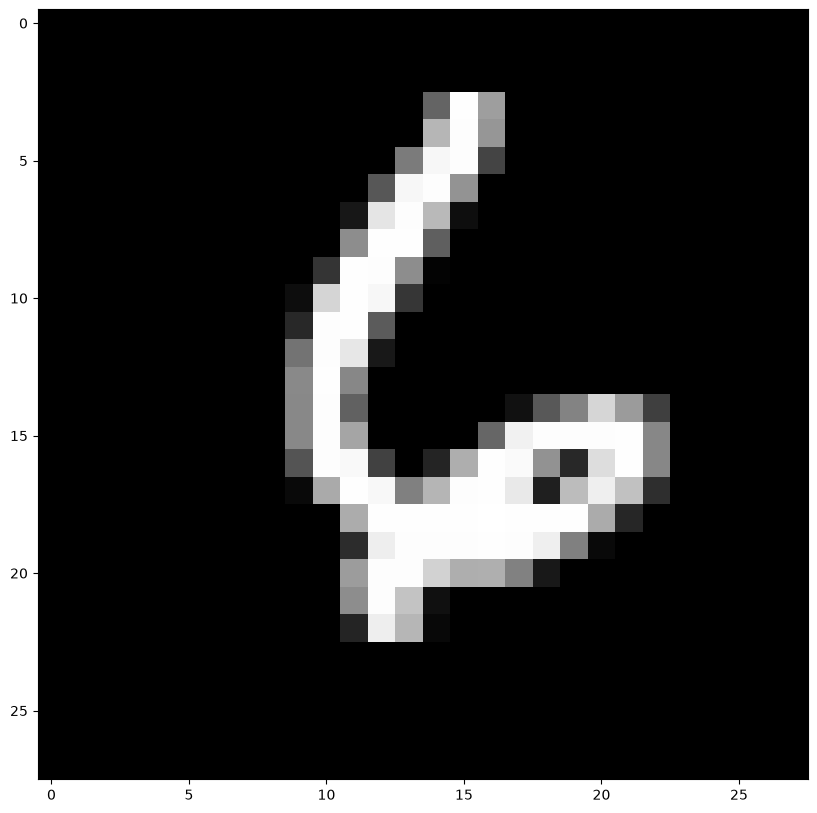

In [9]:
plt.figure(figsize=(10,10))
plt.imshow(X_train[59000],cmap="gray")
plt.show()

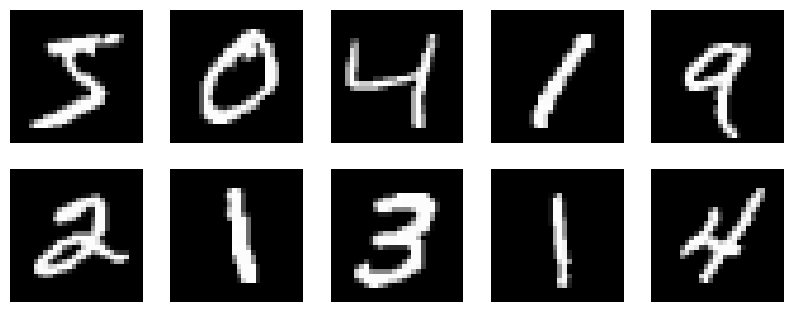

In [10]:
plt.figure(figsize=(10,10))
for n in range(10):
    ax = plt.subplot(5,5,n+1)
    plt.imshow(X_train[n],cmap="gray")
    plt.axis("off")
plt.show()

In [11]:
def visualize_img(data, amount=10):
    plt.figure(figsize=(10,10))
    for n in range(amount):
        ax = plt.subplot(5,5,n+1)
        plt.imshow(data[n], cmap="gray")
        plt.axis('off')
    plt.show()

In [13]:
X_train[2][14:20,10:20]

array([[ 49, 116, 144, 150, 241, 243, 234, 179, 241, 252],
       [254, 250, 240, 198, 143,  91,  28,   5, 233, 250],
       [ 98,  56,   0,   0,   0,   0,   0, 102, 254, 220],
       [  0,   0,   0,   0,   0,   0,   0, 169, 254, 137],
       [  0,   0,   0,   0,   0,   0,   0, 169, 254,  57],
       [  0,   0,   0,   0,   0,   0,   0, 169, 254,  57]], dtype=uint8)

In [15]:
def visualize_pixel(img):
    fig = plt.figure(figsize=(12,12))
    ax = fig.add_subplot(111)
    ax.imshow(img,cmap='gray')
    width,height = img.shape

    threshold = img.max() / 2.5

    for x in range(width):
        for y in range(height):
            ax.annotate(str(round(img[x][y],2)), xy = (y,x), color="white" if img[x][y]<threshold else 'black')

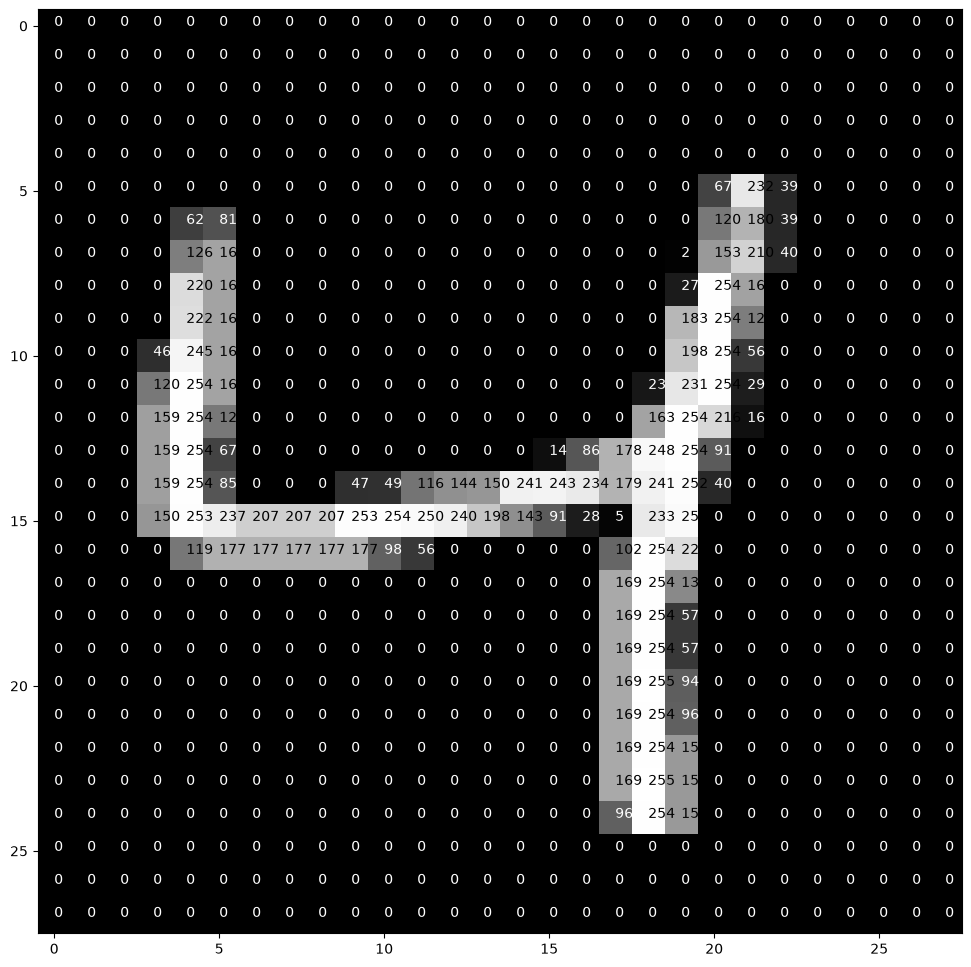

In [16]:
visualize_pixel(X_train[2])

In [20]:
# ENCODING

In [17]:
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

In [21]:
# RESHAPE

In [18]:
img_size = X_train[1]

In [19]:
X_train = X_train.reshape(X_train.shape[0],28,28,1)
X_test = X_test.reshape(X_test.shape[0],28,28,1)

In [23]:
# STANDARDIZATION

In [22]:
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255

In [24]:
# MODELLING

In [25]:
model = tf.keras.Sequential([
    Flatten(input_shape=(28,28,1)),
    Dense(units=128,activation='relu',name="layer1"),
    Dense(units=num_labels, activation='softmax', name='output_layer')
])

In [30]:
model.compile(loss='categorical_crossentropy',
             optimizer='adam',
             metrics=[tf.keras.metrics.Precision(), tf.keras.metrics.Recall(), "accuracy"])

In [28]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ layer1 (Dense)                       │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output_layer (Dense)                 │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
model.fit(X_train,y_train,epochs=5,batch_size=128,validation_data=(X_test,y_test))

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 12s 18ms/step - accuracy: 0.9000 - loss: 0.3600 - precision_2: 0.9455 - recall_2: 0.8491 - val_accuracy: 0.9436 - val_loss: 0.2047 - val_precision_2: 0.9572 - val_recall_2: 0.9292
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9523 - loss: 0.1683 - precision_2: 0.9640 - recall_2: 0.9418 - val_accuracy: 0.9595 - val_loss: 0.1412 - val_precision_2: 0.9670 - val_recall_2: 0.9505
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9654 - loss: 0.1205 - precision_2: 0.9730 - recall_2: 0.9583 - val_accuracy: 0.9656 - val_loss: 0.1160 - val_precision_2: 0.9723 - val_recall_2: 0.9606
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.9735 - loss: 0.0919 - precision_2: 0.9788 - recall_2: 0.9685 - val_accuracy: 0.9694 - val_loss: 0.1046 - val_precision_2: 0.9756 - val_recall_2: 0.9652
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.9789 - loss: 0.0743 - precision_2: 0.9828 - recall_2: 0.975

In [33]:
history = model.fit(X_train,y_train,epochs=10,batch_size=128,validation_data=(X_test,y_test))

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9975 - loss: 0.0119 - precision_2: 0.9980 - recall_2: 0.9972 - val_accuracy: 0.9773 - val_loss: 0.0788 - val_precision_2: 0.9790 - val_recall_2: 0.9762
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9980 - loss: 0.0104 - precision_2: 0.9983 - recall_2: 0.9976 - val_accuracy: 0.9757 - val_loss: 0.0825 - val_precision_2: 0.9773 - val_recall_2: 0.9753
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.9986 - loss: 0.0085 - precision_2: 0.9987 - recall_2: 0.9984 - val_accuracy: 0.9795 - val_loss: 0.0760 - val_precision_2: 0.9811 - val_recall_2: 0.9788
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.9986 - loss: 0.0078 - precision_2: 0.9987 - recall_2: 0.9985 - val_accuracy: 0.9787 - val_loss: 0.0777 - val_precision_2: 0.9799 - val_recall_2: 0.9784
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.9990 - loss: 0.0066 - precision_2: 0.9991 - recall_2: 0.

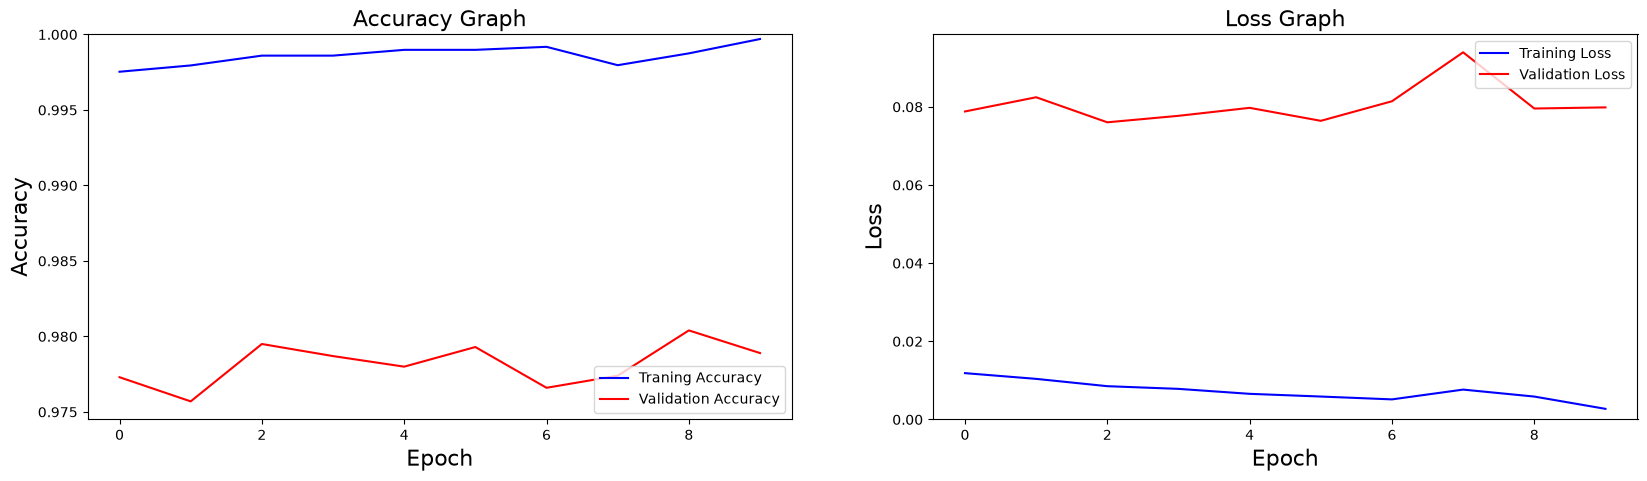

In [35]:
# ------------------------ Graphic 1 ACCURACY ----------------------------

plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'],color='b',label="Traning Accuracy")
plt.plot(history.history['val_accuracy'],color='r', label = "Validation Accuracy")
plt.legend(loc="lower right")
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Accuracy', fontsize=16)
plt.ylim([min(plt.ylim()),1])
plt.title("Accuracy Graph", fontsize=16)

# ------------------------ Graphic 2 LOSS --------------------------------

plt.subplot(1,2,2)
plt.plot(history.history['loss'], color='b', label='Training Loss')
plt.plot(history.history['val_loss'], color='r', label='Validation Loss')
plt.legend(loc="upper right")
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Loss', fontsize=16)
plt.ylim([0,max(plt.ylim())])
plt.title("Loss Graph", fontsize=16)

plt.show()

In [38]:
loss, precision, recall, acc = model.evaluate(X_test,y_test, verbose=False)
print("Test Accuracy: %.1f%%" % (100.0 * acc))
print("Test Loss: %.1f%%" % (100.0 * loss))
print("Test Precision: %.1f%%" % (100.0 * precision))
print("Test Recall: %.1f%%" %  (100.0 * recall))

Test Accuracy: 97.9%
Test Loss: 8.0%
Test Precision: 98.0%
Test Recall: 97.8%


In [39]:
# Save model

In [41]:
model.save("mnist_model.keras")

In [42]:
import random

In [45]:
random_index = random.randint(0, len(X_test) - 1)

In [46]:
test_image = X_test[random_index]

In [47]:
y_test[random_index]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.])

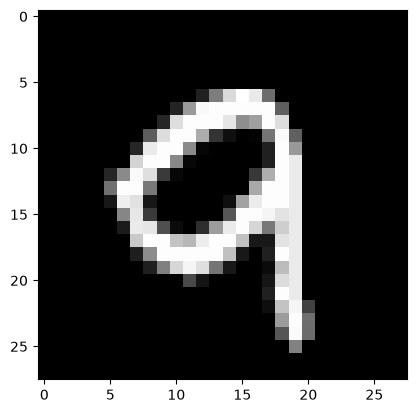

In [48]:
plt.imshow(test_image.reshape(28,28), cmap="gray")
plt.show()

In [49]:
test_data = X_test[random_index].reshape(1,28,28,1)

In [50]:
probability = model.predict(test_data)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step


In [51]:
predicted_classes = np.argmax(probability)

In [52]:
predicted_classes

np.int64(9)

In [53]:
print(f"Predicted Class: {predicted_classes}")
print(f"Predicted Classes Probability: {(np.max(probability, axis=-1))[0]}")
print(f"Other Classes Probability: {probability}")

Predicted Class: 9
Predicted Classes Probability: 0.9999061822891235
Other Classes Probability: [[4.5889490e-07 1.7704681e-13 4.4293367e-05 4.5300359e-05 4.4076981e-07
  8.2624507e-10 4.4048593e-10 1.4126847e-06 1.9157837e-06 9.9990618e-01]]
